# ARIEL: Modules

In [1]:
from ariel.rendering import (  # chooses the OpenGL backend before MuJoCo loads
    single_frame_renderer,
)

One-off setup: testing which OpenGL backends work on this machine. The result is saved to mujoco_user_config.json; 
this will not be repeated.

Output()

In [2]:
# Third-party imports
import matplotlib.pyplot as plt
import mujoco as mj
import numpy as np

In [3]:
# Ariel imports
from ariel.body_phenotypes.robogen_lite.config import ModuleFaces
from ariel.body_phenotypes.robogen_lite.prebuilt_robots.parts import (
    brick,
    build,
    hinge,
)
from ariel.parameters import ArielModulesConfig
from ariel.simulation.environments import SimpleFlatWorld

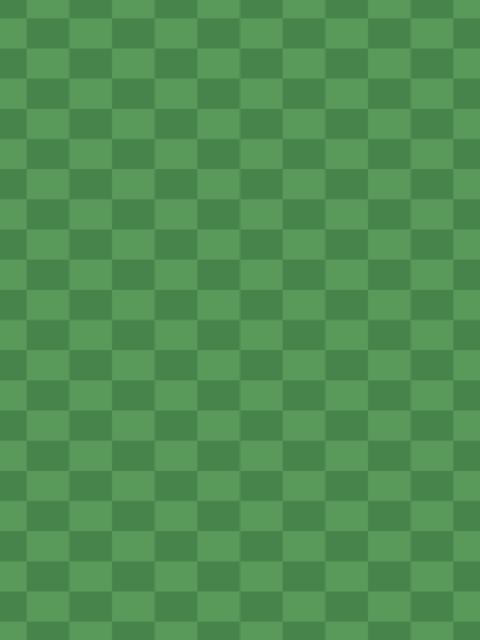

In [4]:
mj.set_mjcb_control(None)
world = SimpleFlatWorld()
model = world.compile()
data = mj.MjData(model)
mj.mj_resetData(model, data)
single_frame_renderer(model, data)

## A hinge is a DSS-M15

Every hinge drives its limb like the DFRobot DSS-M15 servo at 6 V (goal servo-dynamics): its torque is capped at the stall torque, and like any DC motor it loses torque in a straight line as it speeds up, reaching none at the no-load speed. Below, a hinge on a core held in place swings a brick from -90 to +90 degrees against a steady load torque, with gravity and contacts off; its top speed for each load should sit on the datasheet's line.

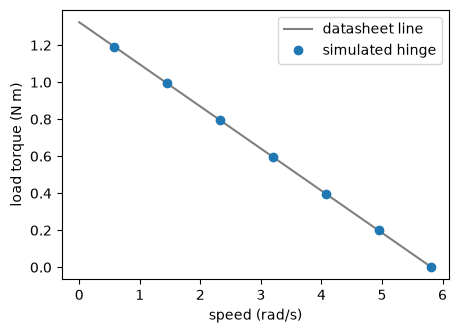

In [5]:
modules = ArielModulesConfig()
stall = modules.servo_settings.stall_torque(modules.servo).value
top_speed = modules.servo_settings.no_load_speed(modules.servo).value


def top_speed_against(load: float) -> float:
    robot = build((
        hinge(1, "core", ModuleFaces.FRONT),
        brick(2, "hinge_0", ModuleFaces.FRONT),
    ))
    world = SimpleFlatWorld()
    world.spawn(
        robot.spec, position=(0, 0, 0.5), correct_collision_with_floor=False
    )
    for joint in list(world.spec.joints):
        if joint.type == mj.mjtJoint.mjJNT_FREE:
            world.spec.delete(joint)  # hold the core in place
    world.spec.option.disableflags |= mj.mjtDisableBit.mjDSBL_CONTACT
    world.spec.option.gravity = np.zeros(3)
    model = world.compile()
    data = mj.MjData(model)
    data.qpos[0], data.ctrl[0] = -np.pi / 2, np.pi / 2
    data.qfrc_applied[0] = -load  # the load resists the turn
    speeds = []
    for _ in range(round(0.5 / model.opt.timestep)):
        mj.mj_step(model, data)
        speeds.append(data.qvel[0])
    return max(speeds)


loads = np.linspace(0, 0.9 * stall, 7)
measured = np.array([top_speed_against(load) for load in loads])
line = stall * (1 - measured / top_speed)

fig, axis = plt.subplots(figsize=(5, 3.5))
axis.plot([0, top_speed], [stall, 0], color="grey", label="datasheet line")
axis.plot(measured, loads, "o", label="simulated hinge")
axis.set_xlabel("speed (rad/s)")
axis.set_ylabel("load torque (N m)")
axis.legend()
plt.show()

In [6]:
assert np.allclose(loads, line, atol=0.02 * stall)
assert measured.max() <= top_speed * 1.005